<a href="https://colab.research.google.com/github/knou-park/DataAnalysis/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_13%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13강 반정형 데이터 분석 : 게시판 글 데이터 활용

### 목표

방송통신대학교 학생 게시판의 글 제목을 수집하고 분석하여, 반정형 데이터의 수집부터 텍스트 분석까지 전체 과정을 실습

### 분석 프로세스 개요

1. 데이터 수집
  - selenium을 활용한 웹 페이지 접근
  - lxml을 이용한 HTML 파싱
  - 게시글 제목 추출

2. 텍스트 데이터 전처리
  - 정규식을 활용한 텍스트 정제
  - 형태소 분석을 통한 명사 추출

3. 키워드 분석
  - 단어 빈도 분석
  - 워드 클라우드 생성
  - 주요 키워드 추출

4. 텍스트 분류 및 시각화
  - LLM을 활용한 텍스트 분류
  - 분류 결과 시각화
  - 인사이트 도출


# 주의 : 런타임 GPU 로 설정 필요

In [2]:
# LLM 처리를 위한 VLLM 설치 (오래걸리는 작업이므로 미리 실행!)
!pip install vllm
# 필요 시 세션 재시작

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 81.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 56.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.7/504.7 kB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 87.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 49.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 78.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6

In [1]:
# 한글 처리를 위한 matplotlib 설정 (1)

!sudo apt-get install -y fonts-nanum
!sudo fc-cache –fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (32.9 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 127332 files and 

- 런타임 -> 세션 다시 시작

In [1]:
# 한글 처리를 위한 matplotlib 설정 (2)

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

# 1. 데이터 수집 및 전처리

## 13-1 웹 스크래핑 라이브러리 설치

In [2]:
!pip install google-colab-selenium lxml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 113.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.8/511.8 kB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 120.6 MB/s eta 0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


## 13-2 웹 스크래핑 함수 정의 및 실행

In [3]:
import google_colab_selenium as gs
from lxml import html

## URL로부터 페이지 내용 가져오기
def get_page(driver, url):
    # url 페이지로 이동
    driver.get(url)
    # 해당 페이지의 html을 page_content로 저장
    page_content = driver.page_source
    # page_content를 lxml의 html 객체로 변환하고 tree로 저장
    tree = html.fromstring(page_content)
    return tree

## HTML 트리에서 제목 추출
def extract_titles(tree):
    ## td-subject를 클래스로 가지는 td 태그 > a태그 > string > text() 을 xpath로 구하고 titles로 저장
    titles = tree.xpath('//td[@class = "td-subject"]/a/strong/text()')
    return titles

## 제목 목록 출력
def print_titles(titles):
    for title in titles:
        print(title)

## Chrome 드라이버 초기화
driver = gs.Chrome()

## 컴퓨터과학과 게시판 첫번째 페이지 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
tree = get_page(driver, board_url)
titles = extract_titles(tree)
print_titles(titles)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!     
연극치료 임상실습 참여자 모집
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
웹 소설 '연극치료사' 
과제물, 학습자료 가기
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정


## 13-3 다중 페이지 데이터 수집 및 데이터프레임 생성

In [6]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
import pandas as pd

## 다음 페이지로 이동하고 tree 정보 반환
def move_to_next_page(driver):
    # _listNext 클래스를 기준으로 엘리먼트 선택
    next_page_link = driver.find_element(By.CLASS_NAME, "_listNext")
    if next_page_link and next_page_link.is_enabled():
        # 다음 페이지 버튼 클릭
        next_page_link.click()
        WebDriverWait(driver, 10).until(
            EC.presence_of_element_located((By.CLASS_NAME, "board-table"))
        )
        page_content = driver.page_source
        tree = html.fromstring(page_content)
        return tree
    else:
        return None

## 여러 페이지에서 게시물 제목 가져오기
def get_board_titles(url, pages, verbose=False):
    driver = gs.Chrome()
    board_titles = []
    for page in pages:
        if verbose:
          print(f"=== 페이지 {page} 처리중입니다. ===")
        if page == 1:
            # 13-2 에서 작성한 get_page 함수를 이용하여 현재 페이지 tree 구하기
            tree = get_page(driver, url)
        else:
            # 다음 페이지로 이동하고 해당 페이지 tree 구하기
            tree = move_to_next_page(driver)
        if tree is not None:
            titles = extract_titles(tree)
            board_titles.extend(titles)
            if verbose:
              print_titles(titles)
    driver.quit()  # Chrome 드라이버 종료
    return board_titles

## 컴퓨터과학과 게시판 1 페이지 ~ 10 페이지의 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=True)
## 컴퓨터과학과 제목 데이터프레임 생성
cs_df = pd.DataFrame(data = {'제목': board_titles})

<IPython.core.display.Javascript object>

=== 페이지 1 처리중입니다. ===
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!     
연극치료 임상실습 참여자 모집
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
웹 소설 '연극치료사' 
과제물, 학습자료 가기
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정
=== 페이지 2 처리중입니다. ===
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
미래내일 일경험 기업 실무 프로젝트 참여자 모집 (~9/20)
2026 AI 트렌드 온라인 특강
🚨🚨방통대. 방송대학생들 다 모였다! 국내 최대 온라인 학생 커뮤니티 사이트🚨🚨
방송대 모든 학과 과제&기출 창고
창작과 공연을 이어가는 연극동아리에서 회원을 모집합니다.
📢오랜 전통의 극예술연구회에서 신입 회원을 모집합니다🎵
극예술연구회   회원모집
 ★ 극예술연구회 ★ 연극동아리 49기 신입 회원 모집
=== 페이지 3 처리중입니다. ===
2학기 학습 자료 및 기출문제 안내[방송대 방모창] 
🚨🚨방통대생들 다 모였다! 국내 최대 온라인 학생모임 ‘방송대인’🚨🚨
🚨🚨방통대생들 다 모였다! 국내 최대 온라인 학생모임 ‘방송대인’🚨🚨
🔔 "방송대 공지사항 알리미"가 새로 생겼습니다!!! 🔔카카오톡 단톡
※ 연극동아리(극예술연구회) 49기 신입단원( 배우 및 스텝)모집 ※
연극
📢오랜 전통의 극예술연구회에서 신입 회원을 모집합니다🎵
🔔평점 4.5점 만점자 전화 인터뷰 들으러 가기🔔치킨 기프티콘🔔네이버 대표카페🔔참고
'학습 품앗이 3·3·3 캠페인’으로 서로 채워주는 방송대 
📚 방통신(

# 2. 텍스트 데이터 전처리

## 13-4 정규식을 활용한 텍스트 정제

In [7]:
import re

## 텍스트 정제 함수
def clean_text(text):
    if isinstance(text, str):
       # 특수 문자 제거 regex (영어 소문자, 영어 대문자, 숫자, 한글, 공백글자만 허용)
       text = re.sub(r'[^a-zA-Z0-9가-힣\s]', '', text)
       # HTML 태그 제거 regex
       text = re.sub(r'<[^>]*>', '', text)
       # 소문자로 변환 python 함수
       text = text.lower()
       return text
    else:
        return ""

## 데이터프레임 정제 함수
def clean_df(df):
  if not df.empty:
      df['정제된 제목'] = df['제목'].apply(clean_text)

## cs_df에 정제 함수 적용
clean_df(cs_df)
cs_df

,제목,정제된 제목
0,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방
1,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를
2,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리
3,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다
4,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집
...,...,...
95,웹 소설 '연극치료사',웹 소설 연극치료사
96,"7월 24일~25일 연극 ""시간이 지나도"" 무료 관람. 본교열린관지하소극",7월 24일25일 연극 시간이 지나도 무료 관람 본교열린관지하소극
97,고려대학교 AI 데이터 인재 전문 인력 양성 프로그램 안내(교육비 전액 무료),고려대학교 ai 데이터 인재 전문 인력 양성 프로그램 안내교육비 전액 무료
98,[2026 방통대] 과제물 작성법 & 감점 방지 제출 체크리스트,2026 방통대 과제물 작성법 감점 방지 제출 체크리스트


## 13-5 형태소 분석기 설치 및 실행 예시

In [8]:
## Kiwi 형태소 분석기 설치
!pip install kiwipiepy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 9.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 37.6 MB/s eta 0:00:00
  Created wheel for kiwipiepy_model: filename=kiwipiepy_model-0.24.0-py3-none-any.whl size=87973829 sha256=545857bfe425971afceb1b1b61fd5bd956a630826a0ce703121667dc3d1027ac
  Stored in directory: /root/.cache/pip/wheels/1e/08/d4/4ff00b71c6b738e5308a0867385c986a743e5307c5206da985
Successfully built kiwipiepy_model


In [10]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')

## 문장 형태소 분석 결과 출력
kiwi.analyze('안녕하세요 저는 방송대 학생입니다.')[0][0]

[Token(form='안녕', tag='NNG', start=0, len=2),
 Token(form='하', tag='XSA', start=2, len=1),
 Token(form='세요', tag='EF', start=3, len=2),
 Token(form='저', tag='NP', start=6, len=1),
 Token(form='는', tag='JX', start=7, len=1),
 Token(form='방송대', tag='NNP', start=9, len=3),
 Token(form='학생', tag='NNG', start=13, len=2),
 Token(form='이', tag='VCP', start=15, len=1),
 Token(form='ᆸ니다', tag='EF', start=15, len=3),
 Token(form='.', tag='SF', start=18, len=1)]

## 13-6 형태소 분석을 통한 품사 분리

In [11]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')
kiwi.add_user_word('방통대', 'NNP')

## 텍스트 형태소 분석 함수
def analyze_morphemes(text):
    if isinstance(text, str):
       result = kiwi.analyze(text)

       morphemes = []
       for token in result[0][0]:
            ## 형태소(form)와 품사(tag) 정보를 튜플로 morphemes에 추가
            morphemes.append((token.form, token.tag))
       return morphemes
    else:
        return []

## 데이터프레임에 형태소 분석 적용 함수
def pos_df(df):
  if not df.empty:
      # `정제된 제목` 칼럼의 값에 analyze_morphemes 함수를 적용하고 결과를 `행태소 분석 결과` 칼럼에 저장
      df['형태소 분석 결과'] = df['정제된 제목'].apply(analyze_morphemes)

## 형태소 분석 적용
pos_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과
0,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)..."
1,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를,"[(우수, NNG), (학습자, NNG), (인터뷰, NNG), (영상, NNG),..."
2,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리,"[(방송대, NNP), (공지, NNG), (사항, NNG), (카톡, NNP), ..."
3,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다,"[(가야, NNP), (역사, NNG), (풍수, NNG), (지리, NNG), (..."
4,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (참여자, NNG)..."
...,...,...,...
95,웹 소설 '연극치료사',웹 소설 연극치료사,"[(웹, NNG), (소설, NNG), (연극, NNG), (치료사, NNG)]"
96,"7월 24일~25일 연극 ""시간이 지나도"" 무료 관람. 본교열린관지하소극",7월 24일25일 연극 시간이 지나도 무료 관람 본교열린관지하소극,"[(7, SN), (월, NNB), (24, SN), (일, NNB), (25, S..."
97,고려대학교 AI 데이터 인재 전문 인력 양성 프로그램 안내(교육비 전액 무료),고려대학교 ai 데이터 인재 전문 인력 양성 프로그램 안내교육비 전액 무료,"[(고려대학교, NNP), (ai, SL), (데이터, NNG), (인재, NNG)..."
98,[2026 방통대] 과제물 작성법 & 감점 방지 제출 체크리스트,2026 방통대 과제물 작성법 감점 방지 제출 체크리스트,"[(2026, SN), (방통대, NNP), (과제물, NNG), (작성, NNG)..."


## 13-7 명사 추출

In [12]:
## 형태소 분석 결과에서 명사 추출
def extract_nouns(morphemes):
  # 형태소가 NNG (일반명사), NNP (고유명사) 인 word를 nouns에 저장
  nouns = [word for word, tag in morphemes if tag in ['NNG', 'NNP']]
  return nouns

## 데이터프레임에 명사 추출 적용
def noun_df(df):
  if not df.empty:
      df['명사'] = df['형태소 분석 결과'].apply(extract_nouns)

## 명사 추출 적용
noun_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과,명사
0,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)...","[크로바, 네이버, 카페, 크로바, 기출, 문제, 카페, 크로바, 학사, 공지, 전..."
1,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를,"[(우수, NNG), (학습자, NNG), (인터뷰, NNG), (영상, NNG),...","[우수, 학습자, 인터뷰, 영상, 온라인, 강의, 노하우, 팁, 공부, 방, 진, ..."
2,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리,"[(방송대, NNP), (공지, NNG), (사항, NNG), (카톡, NNP), ...","[방송대, 공지, 사항, 카톡, 알리미과제길잡이기출과제과제족보, 기출, 문제, 요점..."
3,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다,"[(가야, NNP), (역사, NNG), (풍수, NNG), (지리, NNG), (...","[가야, 역사, 풍수, 지리, 답사, 선착순, 초청]"
4,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (참여자, NNG)...","[연극치료, 임상, 실습, 참여자, 모집]"
...,...,...,...,...
95,웹 소설 '연극치료사',웹 소설 연극치료사,"[(웹, NNG), (소설, NNG), (연극, NNG), (치료사, NNG)]","[웹, 소설, 연극, 치료사]"
96,"7월 24일~25일 연극 ""시간이 지나도"" 무료 관람. 본교열린관지하소극",7월 24일25일 연극 시간이 지나도 무료 관람 본교열린관지하소극,"[(7, SN), (월, NNB), (24, SN), (일, NNB), (25, S...","[연극, 시간, 무료, 관람, 본교열린관지하소극]"
97,고려대학교 AI 데이터 인재 전문 인력 양성 프로그램 안내(교육비 전액 무료),고려대학교 ai 데이터 인재 전문 인력 양성 프로그램 안내교육비 전액 무료,"[(고려대학교, NNP), (ai, SL), (데이터, NNG), (인재, NNG)...","[고려대학교, 데이터, 인재, 전문, 인력, 양성, 프로그램, 안내, 교육비, 전액..."
98,[2026 방통대] 과제물 작성법 & 감점 방지 제출 체크리스트,2026 방통대 과제물 작성법 감점 방지 제출 체크리스트,"[(2026, SN), (방통대, NNP), (과제물, NNG), (작성, NNG)...","[방통대, 과제물, 작성, 법, 감점, 방지, 제출, 체크, 리스트]"


## 13-8 데이터 전처리 통합 함수 정의

In [13]:
## 데이터프레임 전처리 통합 함수
def preprocessing_df(df):
  clean_df(df) ## 텍스트 정제 적용
  pos_df(df) ## 형태소 분석 적용
  noun_df(df) ## 명사 추출 적용

# 3. 키워드 분석

## 13-9 단어 빈도 계산

In [14]:
from collections import Counter

## 데이터프레임에서 단어 빈도 계산
def get_word_count(df):
    if not df.empty:
        # 모든 명사의 리스트를 구함
        all_nouns = df['명사'].sum()
        # 모든 명사들에 대한 Counter 객체(빈도 정보) 를 반환
        return Counter(all_nouns)

## cs_df의 단어 빈도 계산
word_count = get_word_count(cs_df)
print("단어 빈도:")
## 상위 30개 단어(most_common)의 빈도 출력
for word, freq in word_count.most_common(30):
    print(f"{word}: {freq}")

단어 빈도:
모집: 39
연극: 33
신입: 26
회원: 25
동아리: 24
방송대: 17
기: 17
카페: 13
기출: 13
문제: 13
극예술: 13
연구회: 13
네이버: 12
대표: 11
정리: 9
극예술연구회: 9
참고: 9
요점: 8
학기: 8
온라인: 7
웹: 7
소설: 7
치료사: 7
방통대: 7
전통: 7
공지: 6
인터뷰: 6
사항: 6
교재: 6
장터: 6


## 13-10 워드클라우드 생성 및 시각화

In [15]:
## WordCloud 라이브러리 설치
!pip install wordcloud

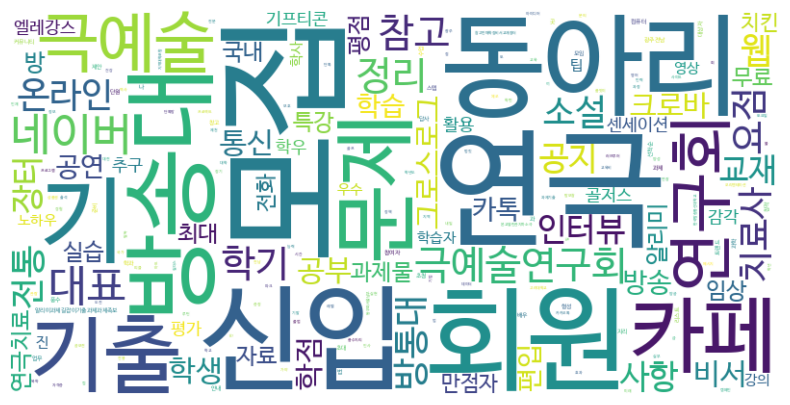

In [16]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

## 단어 빈도를 바탕으로 워드클라우드 생성 및 표시
def plot_wordcloud(word_count):
    ## 워드 클라우드 생성
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis',
        font_path='/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf' ## 한글 폰트 경로 지정
        ).generate_from_frequencies(word_count) # word_count의 빈도 정보를 이용하여 생성

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear') ## 이미지 표시
    plt.axis("off") ## 축 비활성화
    plt.show() ## 그래프 표시

## cs_df에서 단어 빈도 계산
word_count = get_word_count(cs_df)
## 워드클라우드 생성 및 표시
plot_wordcloud(word_count)

## 13-11 다른 학과의 워드 클라우드 생성

<IPython.core.display.Javascript object>

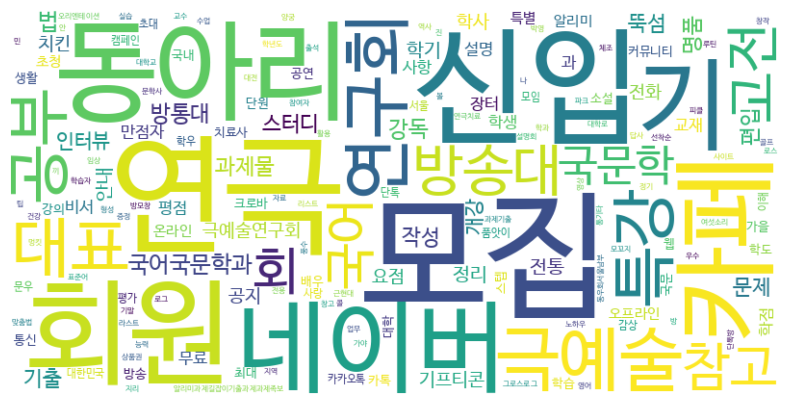

In [28]:
board_name = '국어국문학과'
board_url = 'https://korean.knou.ac.kr/korean/5323/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
ko_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(ko_df)
word_count = get_word_count(ko_df)
plot_wordcloud(word_count)

<IPython.core.display.Javascript object>

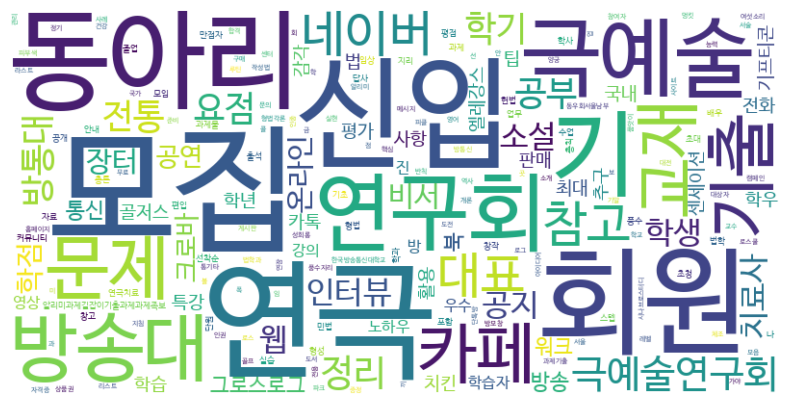

In [29]:
board_name = '법학과'
board_url = 'https://law.knou.ac.kr/law/5176/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
law_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(law_df)
word_count = get_word_count(law_df)
plot_wordcloud(word_count)

# 4. 텍스트 분류 및 시각화

## 13-12 VLLM 라이브러리 설치 및 LLM 모델 로드

주의
- 런타임 유형 : GPU
- 라이브러리 설치 및 모델 다운로드에 수 분(>6분)의 시간이 소요됩니다.


In [18]:
from vllm import LLM

## LLM 모델 로드 및 설정
llm = LLM(
    model="LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct",
    tensor_parallel_size=1,
    dtype="half",
    gpu_memory_utilization=0.6,
    max_model_len = 32000,
    trust_remote_code=True
)

(MainProcess pid=3143) INFO 10-19 16:31:04 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'dtype': 'half', 'max_model_len': 32000, 'gpu_memory_utilization': 0.6, 'disable_log_stats': True, 'model': 'LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct'}


configuration_exaone.py:   0%|          | 0.00/11.3k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct:
- configuration_exaone.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


(MainProcess pid=3143) INFO 10-19 16:31:45 [model.py:733] Resolved architecture: ExaoneForCausalLM
(MainProcess pid=3143) INFO 10-19 16:31:45 [model.py:2495] Downcasting torch.float32 to torch.float16.
(MainProcess pid=3143) INFO 10-19 16:31:45 [model.py:2152] Using max model len 32000
(MainProcess pid=3143) INFO 10-19 16:31:45 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.


model.safetensors.index.json:   0%|          | 0.00/22.2k [00:00<?, ?B/s]

...

(EngineCore pid=20660) INFO 10-19 16:40:55 [backends.py:398] [backbone] Compiling a graph for compile range (1, 8192) takes 11.46 s
(EngineCore pid=20660) INFO 10-19 16:40:59 [backends.py:927] collected artifacts: 31 entries, 3 artifacts, 4605029 bytes total
(EngineCore pid=20660) INFO 10-19 16:40:59 [decorators.py:743] [backbone] saved AOT compiled function to /root/.cache/vllm/torch_compile_cache/torch_aot_compile/43c161dbf5dc555b774da30611e33cd5c6d3d24b3f05cd0ba209b1e5c2f83b80/rank_0_0/model
(EngineCore pid=20660) INFO 10-19 16:40:59 [monitor.py:62] [backbone] torch.compile took 24.78 s in total
(EngineCore pid=20660) INFO 10-19 16:41:00 [monitor.py:91] [backbone] Initial profiling/warmup run took 0.25 s


Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00,  6.81it/s]


(EngineCore pid=20660) INFO 10-19 16:41:16 [model_runner.py:1127] Graph capturing finished in 12 secs, took 0.31 GiB
(EngineCore pid=20660) INFO 10-19 16:41:17 [gpu_worker.py:759] Available KV cache memory: 3.04 GiB
(EngineCore pid=20660) INFO 10-19 16:41:17 [gpu_worker.py:774] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.6000 is equivalent to --gpu-memory-utilization=0.5749 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.6251. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=20660) INFO 10-19 16:41:17 [kv_cache_utils.py:2327] GPU KV cache size: 42,480 tokens, Maximum concurrency for 32,000 tokens per request: 1.33x
(EngineCore pid=20660) INFO 10-19 16:41:17 [kernel_warmup.py:176] JIT kernel warmup starting.
(EngineCore pid=20660) INFO 10-19 16:41:17 [kernel_warmup.py:189] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:02<00:00, 14.31it/s]


(EngineCore pid=20660) INFO 10-19 16:41:51 [model_runner.py:1127] Graph capturing finished in 10 secs, took 0.19 GiB
(EngineCore pid=20660) INFO 10-19 16:41:51 [gpu_worker.py:971] CUDA graph pool memory: 0.19 GiB (actual), 0.37 GiB (estimated), difference: 0.18 GiB (96.8%).
(EngineCore pid=20660) INFO 10-19 16:41:51 [gpu_worker.py:1034] Free memory on device (14.46/14.56 GiB) on startup. Desired GPU memory utilization is (0.6, 8.74 GiB). Actual usage is 4.78 GiB for consumed memory (weights + non-torch), 0.92 GiB for peak activation, and 0.19 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=2906333901` (2.71 GiB) to fit into requested memory, or `--kv-cache-memory=9051198976` (8.43 GiB) to fully utilize gpu memory. Current kv cache memory in use is 3.04 GiB.
(EngineCore pid=20660) INFO 10-19 16:41:52 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=20660) INFO 10-19 1

## 13-13 LLM 샘플링 파라미터 설정 및 프롬프트 생성

In [20]:
from vllm import SamplingParams ## SamplingParams 클래스 임포트

## 샘플링 파라미터 설정
sampling_params = SamplingParams(
    temperature=0.3, ## 생성 텍스트의 다양성 조절
    top_p=1.0, ## top_p 누적 확률 내에서 토큰 샘플링
    max_tokens=512, ## 생성될 최대 토큰 수
    frequency_penalty=0.5 ## 자주 나타나는 토큰에 대한 패널티
)

def format_prompt(user_input: str) -> str:
    ## 프롬프트 형식화 함수
    messages = [
        {"role": "system", "content": "You are EXAONE model from LG AI Reseach, a helpful assistant."}, # 시스템 메시지 추가
        {"role": "user", "content": user_input} # 사용자 메시지 추가
    ]
    return messages

## 프롬프트 생성
prompt = format_prompt("대한민국의 수도는 어디인가요? 수도에 여행하러간다면 어떤 즐길거리가 있을까요?")

## LLM을 사용하여 텍스트 생성
# chat 함수를 이용 (프롬프트와 샘플링 파라미터)
outputs = llm.chat(prompt, sampling_params)

## 생성된 텍스트 출력
print("\n생성된 텍스트:", outputs[0].outputs[0].text)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:11<00:00, 11.99s/it, est. speed input: 4.92 toks/s, output: 32.71 toks/s]


생성된 텍스트: 대한민국의 수도는 **서울**입니다. 서울은 역사적인 유적지와 현대적인 문화 시설이 공존하는 매력적인 도시로, 다양한 관광 명소를 자랑합니다:

1. **경복궁**: 조선 시대의 궁궐로, 아름다운 정원과 전통 건축물이 조화를 이루고 있어 역사적 가치가 높습니다.
2. **인사이트 타워**: 서울스카이 전망대에서 서울 시내 전경을 감상할 수 있어 멋진 전망을 제공합니다.
3. **국립중앙박물관**: 한국의 역사와 문화를 한눈에 볼 수 있는 곳으로, 다양한 전시물이 있습니다.
4. **한강공원**: 한강을 따라 걷거나 자전거를 타며 자연을 즐길 수 있으며, 특히 밤에는 조명으로 장식된 한강 야경이 아름답습니다.
5. **명동 및 명동역**: 쇼핑과 엔터테인먼트의 중심지로, 다양한 브랜드 매장과 카페가 즐비합니다.
6. **북촌 한옥마을**: 전통 한옥 마을로, 고요하고 아름다운 분위기 속에서 한국의 전통 문화를 체험할 수 있습니다.
7. **한강공원 내 스포츠 시설**: 축구 경기장이나 야구장 등에서 스포츠 경기 관람도 가능합니다 (예: KBO 리그 경기).
8. **서울숲 및 올림픽공원**: 자연 친화적인 공간으로 산책이나 피크닉을 즐기기에 좋습니다. 특히 올림픽공원은 다양한 이벤트와 전시가 열립니다.
9. **롯데월드타워 스카이데크**: 서울스카이 전망대 외에도 타워 내 쇼핑몰과 레스토랑에서 현대적인 경험을 즐길 수 있습니다.
10. **전통시장 방문**: 남대문시장이나 동대문시장 등에서 현지 음식과 기념품을 구매할 수 있어 독특한 경험이 될 것입니다.

이러한 장소들은 서울 여행의 핵심 포인트로, 역사와 현대가 어우러진 다채로운 경험을 제공합니다!


## 13-14 LLM 기반 분류 프롬프트 및 함수 정의

In [21]:
## 분류 프롬프트 형식화 함수
def format_classifier_prompt(board_title, title) -> str:
    messages = [
        {"role": "system", "content": "You are EXAONE model from LG AI Research, a helpful assistant."},
        {"role": "user", "content": """주어진 글의 제목을 분류하는 AI 모델입니다.
분류 클래스는 학사/전공, 학생활동, 외부정보로 나뉘어집니다.
- 학사/전공: 교재, 과제, 시험 등 학업 및 전공 관련 내용
- 학생활동: 동아리, 스터디, 모임 등 학생들의 자발적 활동
- 외부정보: 취업, 공모전, 행사 등 외부 정보"""},
        {"role": "user", "content": """예시)
전공명: 컴퓨터학과, 제목: 프로그래밍 과제 질문 -> 학사/전공
전공명: 컴퓨터학과, 제목: 알고리즘 스터디 모집 -> 학생활동
전공명: 컴퓨터학과, 제목: IT 취업 박람회 -> 외부정보"""},
        {"role": "user", "content": f"전공명: {board_title}\n제목: {title}"}
    ]
    return messages

## 분류 수행 함수
def classify(major, title):
    prompt = format_classifier_prompt(major, title) ## 분류 프롬프트 생성
    outputs = llm.chat([prompt], sampling_params) ## LLM으로 분류 실행
    return outputs[0].outputs[0].text ## 분류 결과 텍스트 반환

In [22]:
classify('컴퓨터학과', '딥러닝 개발 중에 질문 있습니다.')

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.93s/it, est. speed input: 100.39 toks/s, output: 32.08 toks/s]


'**분류 결과:** 학사/전공  \n**이유:** 딥러닝 개발 과정에서의 질문은 주로 학업 내용과 직접 연관되어 있으며, 컴퓨터학과 학생이나 연구자로서의 학습 및 연구 활동에 해당하므로 **학사/전공** 분류에 속합니다.'

In [23]:
classify('컴퓨터학과', '연극 동아리 회원 모집!! 신규 단원 혜택! AI로 배우는 연극!')

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.15s/it, est. speed input: 92.58 toks/s, output: 32.10 toks/s]


'**분류 결과:** 학생활동  \n**설명:** 제목이 연극 동아리의 회원 모집과 관련된 내용을 포함하고 있으며, 특히 "신규 단원 혜택"과 "AI로 배우는 연극"이라는 문구는 학생들의 자발적인 참여와 활동을 강조하고 있어 학생활동 범주에 속합니다.'

## 13-15 분류 결과 파싱 함수 정의

In [24]:
def get_class(analysis_result):
    ## 분석 결과에서 분류 클래스 추출
    classes = ['학사/전공', '학생활동', '외부정보', '기타']
    classes_index = [analysis_result.find(cls) for cls in classes]

    min_index = float('inf')
    min_class = '기타'

    for i in range(len(classes)):
        current_index = classes_index[i]
        if current_index != -1 and current_index < min_index:
            min_index = current_index
            min_class = classes[i]

    return min_class

In [25]:
## 컴퓨터과학과 제목 분류 헬퍼 함수 정의
def classify_cs(title):
  return classify('컴퓨터과학과', title)

## '제목' 컬럼에 분류 함수 적용하여 분석 결과 저장
cs_df['class_analysis'] = cs_df['제목'].apply(classify_cs)
## 분석 결과에서 최종 분류 클래스 추출하여 저장
cs_df['class'] = cs_df['class_analysis'].apply(get_class)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.81s/it, est. speed input: 75.22 toks/s, output: 31.73 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:07<00:00,  7.83s/it, est. speed input: 27.84 toks/s, output: 30.91 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

...

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  4.56it/s, est. speed input: 918.82 toks/s, output: 36.75 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.03s/it, est. speed input: 100.21 toks/s, output: 35.05 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.16s/it, est. speed input: 91.26 toks/s, output: 34.74 toks/s]


In [26]:
cs_df

,제목,정제된 제목,형태소 분석 결과,명사,class_analysis,class
0,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)...","[크로바, 네이버, 카페, 크로바, 기출, 문제, 카페, 크로바, 학사, 공지, 전...",제목: 🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방\...,학사/전공
1,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를,"[(우수, NNG), (학습자, NNG), (인터뷰, NNG), (영상, NNG),...","[우수, 학습자, 인터뷰, 영상, 온라인, 강의, 노하우, 팁, 공부, 방, 진, ...",주어진 제목들을 분류하면 다음과 같습니다:\n\n1. **📢우수 학습자 인터뷰 영상...,학생활동
2,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리,"[(방송대, NNP), (공지, NNG), (사항, NNG), (카톡, NNP), ...","[방송대, 공지, 사항, 카톡, 알리미과제길잡이기출과제과제족보, 기출, 문제, 요점...","제목: **학사/전공**\n\n**설명:**\n제목에 포함된 키워드들 (""과제"", ...",학사/전공
3,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!,가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다,"[(가야, NNP), (역사, NNG), (풍수, NNG), (지리, NNG), (...","[가야, 역사, 풍수, 지리, 답사, 선착순, 초청]","제목: ""가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!""\n\n**분류:...",외부정보
4,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (참여자, NNG)...","[연극치료, 임상, 실습, 참여자, 모집]",제목: **학생활동**,학생활동
...,...,...,...,...,...,...
95,웹 소설 '연극치료사',웹 소설 연극치료사,"[(웹, NNG), (소설, NNG), (연극, NNG), (치료사, NNG)]","[웹, 소설, 연극, 치료사]",제목: **웹 소설 '연극치료사'**\n\n**분류: 학생활동**\n\n**이유:*...,학생활동
96,"7월 24일~25일 연극 ""시간이 지나도"" 무료 관람. 본교열린관지하소극",7월 24일25일 연극 시간이 지나도 무료 관람 본교열린관지하소극,"[(7, SN), (월, NNB), (24, SN), (일, NNB), (25, S...","[연극, 시간, 무료, 관람, 본교열린관지하소극]","제목: ""7월 24일~25일 연극 '시간이 지나도' 무료 관람. 본교 열린관 지하소...",학생활동
97,고려대학교 AI 데이터 인재 전문 인력 양성 프로그램 안내(교육비 전액 무료),고려대학교 ai 데이터 인재 전문 인력 양성 프로그램 안내교육비 전액 무료,"[(고려대학교, NNP), (ai, SL), (데이터, NNG), (인재, NNG)...","[고려대학교, 데이터, 인재, 전문, 인력, 양성, 프로그램, 안내, 교육비, 전액...",**분류 결과:** 외부정보,외부정보
98,[2026 방통대] 과제물 작성법 & 감점 방지 제출 체크리스트,2026 방통대 과제물 작성법 감점 방지 제출 체크리스트,"[(2026, SN), (방통대, NNP), (과제물, NNG), (작성, NNG)...","[방통대, 과제물, 작성, 법, 감점, 방지, 제출, 체크, 리스트]",**분류 결과:** 학사/전공 \n**설명:** 제목은 컴퓨터과학과 학생들의 학업...,학사/전공


## 13-17 분류 결과 시각화

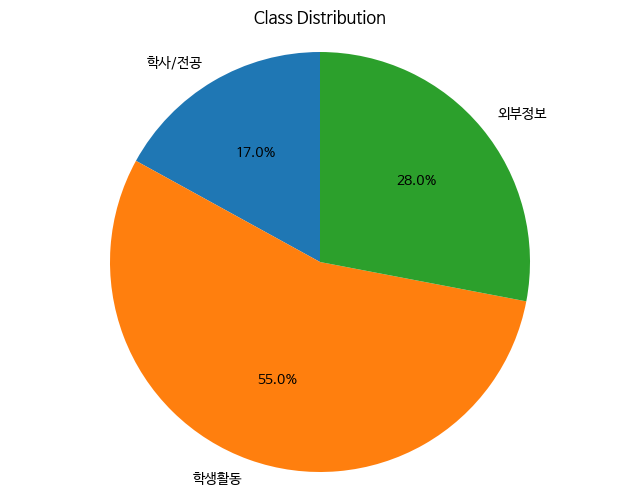

In [27]:
def plot_class(df):
  ## 분류 클래스별 개수 계산 및 순서 재정렬
  class_counts = df['class'].value_counts().reindex(['학사/전공', '학생활동', '외부정보'])

  plt.figure(figsize=(8, 6)) ## 그래프 크기 설정
  plt.pie(class_counts,
          labels=class_counts.index,
          autopct='%.1f%%', ## 퍼센트 표시 형식
          startangle=90, ## 시작 각도 설정
          )

  plt.title('Class Distribution') ## 그래프 제목 설정
  plt.axis('equal') ## 원형 비율 유지
  plt.show() ## 그래프 표시

plot_class(cs_df)

## 13-18 다른 학과의 분류 결과 시각화

In [30]:
def classify_ko(title):
  return classify('국어국문학과', title)

ko_df['class_analysis'] = ko_df['제목'].apply(classify_ko)
ko_df['class'] = ko_df['class_analysis'].apply(get_class)

def classify_law(title):
  return classify('법학과', title)

law_df['class_analysis'] = law_df['제목'].apply(classify_law)
law_df['class'] = law_df['class_analysis'].apply(get_class)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  3.85it/s, est. speed input: 777.47 toks/s, output: 31.10 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:03<00:00,  3.26s/it, est. speed input: 65.00 toks/s, output: 32.81 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

...

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.80s/it, est. speed input: 104.26 toks/s, output: 35.12 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.81s/it, est. speed input: 107.59 toks/s, output: 34.94 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.17s/it, est. speed input: 157.40 toks/s, output: 35.07 toks/s]


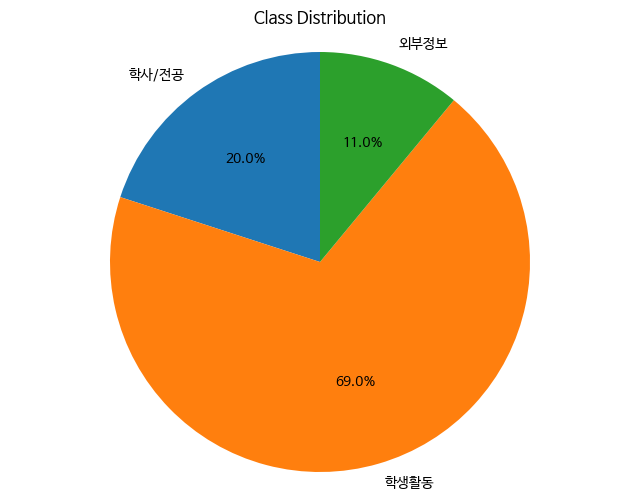

In [31]:
plot_class(ko_df)

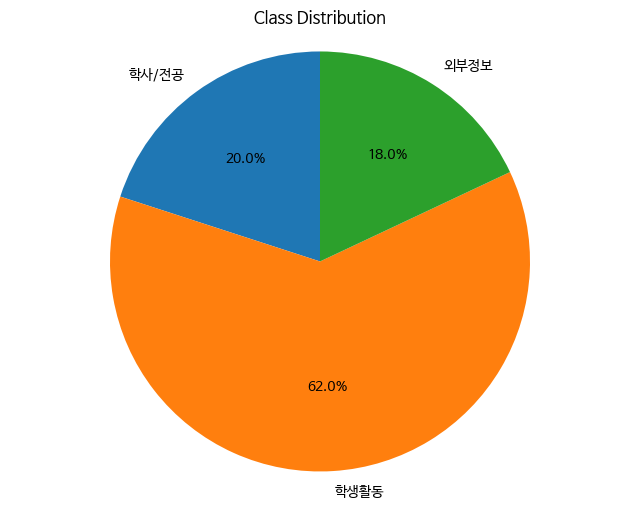

In [32]:
plot_class(law_df)